In [31]:
%matplotlib inline 
%load_ext autoreload
%autoreload 2 --full
import torch
import torchvision
from torch.utils import data
from torchvision import transforms
from matplotlib import pyplot as plt
from dl_utils import Timer
from dl_utils import load_data_fashion_mnist

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
trans = transforms.ToTensor()
mnist_train = torchvision.datasets.FashionMNIST(
    root = "../data", train = True , transform=trans, download=True
)
mnist_test = torchvision.datasets.FashionMNIST(
    root="../data", train=False, transform=trans, download=True
)

In [33]:
len(mnist_train), len(mnist_test)


(60000, 10000)

In [34]:
mnist_train[0][0].shape

torch.Size([1, 28, 28])

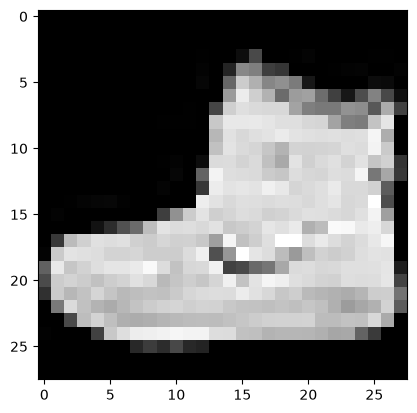

In [35]:
X, y = mnist_train[0]
plt.imshow(X.squeeze(), cmap="gray")
plt.show()

array([<Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 'dress'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 'pullover'}>,
       <Axes: title={'center': 'sneaker'}>,
       <Axes: title={'center': 'pullover'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sneaker'}>,
       <Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 'trouser'}>,
       <Axes: title={'center': 't-shirt'}>], dtype=object)

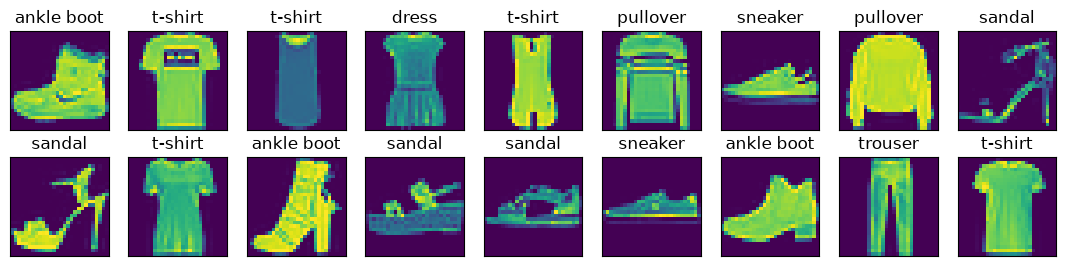

In [36]:
from dl_utils import get_fashion_mnist_labels
from dl_utils import show_images as show_images
X, y = next(iter(data.DataLoader(mnist_train, batch_size=18)))
show_images(X.reshape(18, 28, 28), 2, 9, titles=get_fashion_mnist_labels(y))

In [37]:
batch_size = 256

from dl_utils import get_dataloader_workers

train_iter = data.DataLoader(mnist_train, batch_size, shuffle=True, 
                             num_workers=get_dataloader_workers())

In [38]:
timer = Timer()
for X, y in train_iter:
    continue
f'{timer.stop():.2f} sec'

'6.48 sec'

In [39]:
train_iter, test_iter = load_data_fashion_mnist(32, resize=64)
for X,  y in train_iter:
    print(X.shape, X.dtype, y.shape, y.dtype)
    break

torch.Size([32, 1, 64, 64]) torch.float32 torch.Size([32]) torch.int64
